## 南瓜定价

加载所需的库和数据集。将数据转换为一个包含数据子集的数据框：

- 仅获取按蒲式耳定价的南瓜
- 将日期转换为月份
- 计算价格为高价和低价的平均值
- 将价格转换为反映按蒲式耳数量定价


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from datetime import datetime

pumpkins = pd.read_csv('../../data/US-pumpkins.csv')

pumpkins.head()


,City Name,Type,Package,Variety,Sub Variety,Grade,Date,Low Price,High Price,Mostly Low,...,Unit of Sale,Quality,Condition,Appearance,Storage,Crop,Repack,Trans Mode,Unnamed: 24,Unnamed: 25
0,BALTIMORE,NaN,24 inch bins,NaN,NaN,NaN,4/29/17,270.0,280.0,270.0,...,NaN,NaN,NaN,NaN,NaN,NaN,E,NaN,NaN,NaN
1,BALTIMORE,NaN,24 inch bins,NaN,NaN,NaN,5/6/17,270.0,280.0,270.0,...,NaN,NaN,NaN,NaN,NaN,NaN,E,NaN,NaN,NaN
2,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,9/24/16,160.0,160.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
3,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,9/24/16,160.0,160.0,160.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN
4,BALTIMORE,NaN,24 inch bins,HOWDEN TYPE,NaN,NaN,11/5/16,90.0,100.0,90.0,...,NaN,NaN,NaN,NaN,NaN,NaN,N,NaN,NaN,NaN


In [2]:
pumpkins = pumpkins[pumpkins['Package'].str.contains('bushel', case=True, regex=True)]

columns_to_select = ['Package', 'Variety', 'City Name', 'Low Price', 'High Price', 'Date']
pumpkins = pumpkins.loc[:, columns_to_select]

price = (pumpkins['Low Price'] + pumpkins['High Price']) / 2

month = pd.DatetimeIndex(pumpkins['Date']).month
day_of_year = pd.to_datetime(pumpkins['Date']).apply(lambda dt: (dt-datetime(dt.year,1,1)).days)

new_pumpkins = pd.DataFrame(
    {'Month': month, 
     'DayOfYear' : day_of_year, 
     'Variety': pumpkins['Variety'], 
     'City': pumpkins['City Name'], 
     'Package': pumpkins['Package'], 
     'Low Price': pumpkins['Low Price'],
     'High Price': pumpkins['High Price'], 
     'Price': price})

new_pumpkins.loc[new_pumpkins['Package'].str.contains('1 1/9'), 'Price'] = price/1.1
new_pumpkins.loc[new_pumpkins['Package'].str.contains('1/2'), 'Price'] = price*2

new_pumpkins.head()


C:\Users\24303\AppData\Local\Temp\ipykernel_9924\2637987050.py:9: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  day_of_year = pd.to_datetime(pumpkins['Date']).apply(lambda dt: (dt-datetime(dt.year,1,1)).days)


,Month,DayOfYear,Variety,City,Package,Low Price,High Price,Price
70,9,267,PIE TYPE,BALTIMORE,1 1/9 bushel cartons,15.0,15.0,13.636364
71,9,267,PIE TYPE,BALTIMORE,1 1/9 bushel cartons,18.0,18.0,16.363636
72,10,274,PIE TYPE,BALTIMORE,1 1/9 bushel cartons,18.0,18.0,16.363636
73,10,274,PIE TYPE,BALTIMORE,1 1/9 bushel cartons,17.0,17.0,15.454545
74,10,281,PIE TYPE,BALTIMORE,1 1/9 bushel cartons,15.0,15.0,13.636364


一个基本的散点图提醒我们，我们只有从八月到十二月的月度数据。我们可能需要更多数据才能以线性方式得出结论。


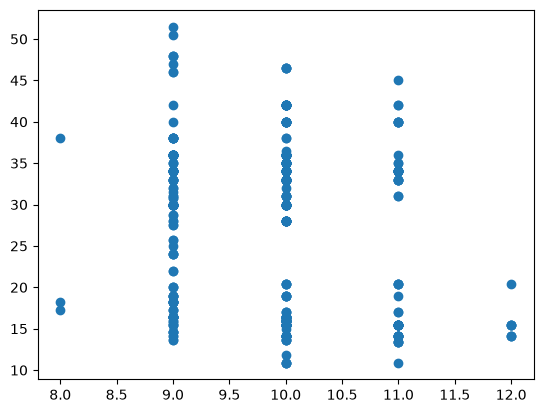

In [3]:
import matplotlib.pyplot as plt

plt.scatter('Month','Price',data=new_pumpkins)

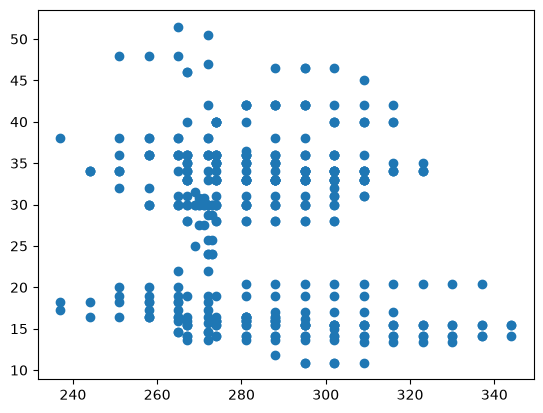

In [4]:
plt.scatter('DayOfYear','Price',data=new_pumpkins)

## 寻找相关性

计算南瓜价格的相关系数

In [5]:
# 计算月份与价格的相关系数
month_corr = new_pumpkins['Month'].corr(new_pumpkins['Price'])

# 计算年内天数与价格的相关系数
day_corr = new_pumpkins['DayOfYear'].corr(new_pumpkins['Price'])

print(f"Month vs Price: {month_corr:.3f}")
print(f"DayOfYear vs Price: {day_corr:.3f}")


Month vs Price: -0.149
DayOfYear vs Price: -0.167


虽然总体的日期与价格相关性很低，但不同品种的南瓜可能有不同的价格分布，因此，转而研究 `Variety`（南瓜品种）

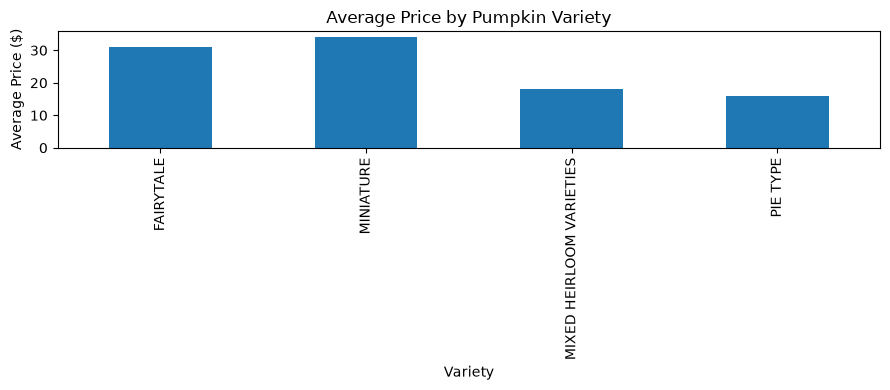

In [6]:
# 观察不同南瓜品种的平均价格
new_pumpkins.groupby('Variety')['Price'].mean().plot(
    kind='bar',
    figsize=(9,4),
    title='Average Price by Pumpkin Variety'
)

plt.ylabel('Average Price ($)')
plt.tight_layout()
plt.show()

暂时只关注“派类型”南瓜，看看日期对价格的影响：

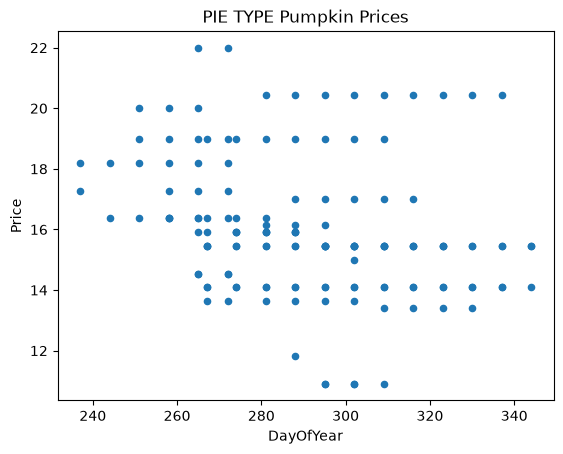

In [7]:
# 筛选 PIE TYPE 品种
pie_pumpkins = new_pumpkins[new_pumpkins['Variety'] == 'PIE TYPE'].copy()

# 清理模型所需字段中的缺失值
pie_pumpkins = pie_pumpkins.dropna(subset=['Price', 'DayOfYear'])

# 观察这一品种的日期与价格关系
pie_pumpkins.plot.scatter(x='DayOfYear', y='Price', title='PIE TYPE Pumpkin Prices')

plt.show()

计算 PIE TYPE 的相关系数

重要的机器学习思路：**当总体数据的规律不明显时，可以尝试按类别分组分析，观察是否存在被整体分布掩盖的规律。**

In [8]:
r = pie_pumpkins['DayOfYear'].corr(pie_pumpkins['Price'])

print(f"PIE TYPE correlation: {r:.3f}")

PIE TYPE correlation: -0.267


## 简单线性回归

### 第一步：准备特征和标签

In [9]:
import numpy as np

from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score

#  特征：年内第几天，标签：南瓜价格
X = pie_pumpkins['DayOfYear'].to_numpy().reshape(-1,1)
y = pie_pumpkins['Price']

print(f"X shape: {X.shape}")
print(f"y shape: {y.shape}")

X shape: (144, 1)
y shape: (144,)


### 第二步：划分训练集和测试集

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=0)

print(f"训练集: {X_train.shape}")
print(f"测试集: {X_test.shape}")

训练集: (115, 1)
测试集: (29, 1)


### 第三步：训练模型

In [11]:
# 创建线性回归模型
lin_reg = LinearRegression()

# 使用训练集拟合模型
lin_reg.fit(X_train, y_train)

print("斜率:", lin_reg.coef_[0])
print("截距:", lin_reg.intercept_)

斜率: -0.017518760953105
截距: 21.133734359909326


### 第四步：预测与模型评估

In [12]:
# 在测试集上预测
pred = lin_reg.predict(X_test)

# 计算测试集 RMSE
rmse = np.sqrt(mean_squared_error(y_test, pred))

# 计算 R²
train_r2 = lin_reg.score(X_train, y_train)
test_r2 = r2_score(y_test, pred)

print(f"RMSE: {rmse:.3f}")
print(f"训练集 R²: {train_r2:.3f}")
print(f"测试集 R²: {test_r2:.3f}")

RMSE: 2.769
训练集 R²: 0.045
测试集 R²: 0.102


### 第五步：画出模型的预测直线

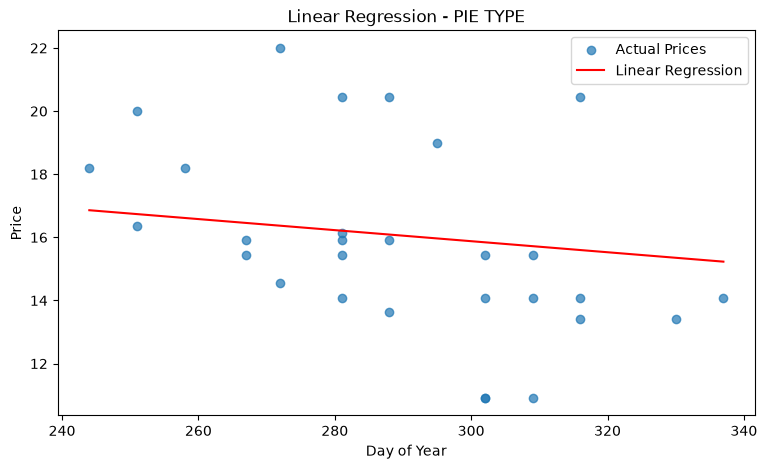

In [13]:

plt.figure(figsize=(9, 5))

# 测试集真实数据
plt.scatter(X_test[:, 0], y_test, label="Actual Prices", alpha=0.7)

# 按日期排序后绘制预测直线
order = np.argsort(X_test[:, 0])

plt.plot(X_test[order, 0], pred[order], color="red", label="Linear Regression")

plt.xlabel("Day of Year")
plt.ylabel("Price")
plt.title("Linear Regression - PIE TYPE")
plt.legend()
plt.show()


## Polynomial Regression

训练二次多项式回归，可视化两个模型差异

In [14]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

# 创建多项式回归流水线
poly_reg = make_pipeline(
    PolynomialFeatures(2),
    LinearRegression()
)

# 使用与线性回归相同的训练集
poly_reg.fit(X_train, y_train)

# 两个模型分别预测同一测试集
linear_pred = lin_reg.predict(X_test)
poly_pred = poly_reg.predict(X_test)

# 对比模型表现
for name, pred in [
    ("Linear Regression", linear_pred),
    ("Polynomial Regression", poly_pred)
]:
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)
    print(f"{name}: RMSE={rmse:.3f}, Test R²={r2:.3f}")


Linear Regression: RMSE=2.769, Test R²=0.102
Polynomial Regression: RMSE=2.730, Test R²=0.127


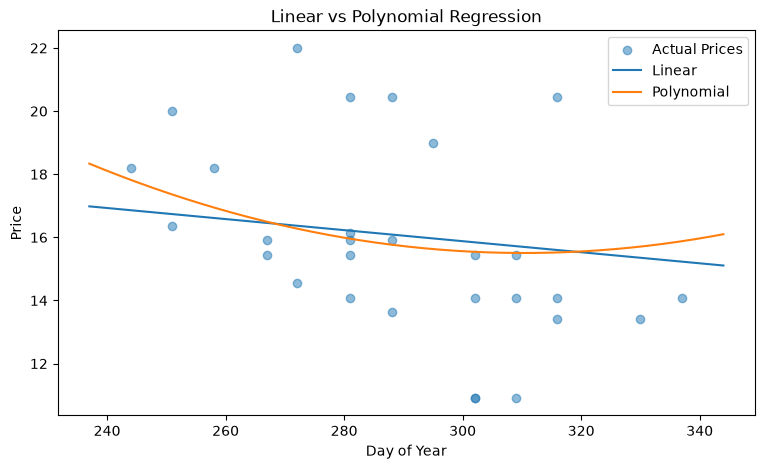

In [15]:
# 生成连续的日期用于绘制平滑曲线
X_curve = np.linspace(X.min(), X.max(), 200).reshape(-1, 1)

plt.figure(figsize=(9, 5))

plt.scatter(X_test[:, 0], y_test, alpha=0.5, label="Actual Prices")

plt.plot(X_curve[:, 0], lin_reg.predict(X_curve), label="Linear")

plt.plot(X_curve[:, 0], poly_reg.predict(X_curve), label="Polynomial")

plt.xlabel("Day of Year")
plt.ylabel("Price")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.show()

## 分类特征

### 独热编码

In [16]:
# 准备新的完整建模数据
model_data = new_pumpkins.dropna(subset=['Variety', 'City', 'Package', 'Month', 'Price']).copy()

# 对南瓜品种进行独热编码
X_variety = pd.get_dummies(model_data['Variety'], dtype=int)
y = model_data['Price']

print(X_variety.head())
print("特征数量:", X_variety.shape[1])

    FAIRYTALE  MINIATURE  MIXED HEIRLOOM VARIETIES  PIE TYPE
70          0          0                         0         1
71          0          0                         0         1
72          0          0                         0         1
73          0          0                         0         1
74          0          0                         0         1
特征数量: 4


In [ ]:
# 划分训练集和测试集
X_train_v, X_test_v, y_train_v, y_test_v = train_test_split(X_variety, y, test_size=0.2, random_state=0)

# 训练模型
variety_model = LinearRegression()
variety_model.fit(X_train_v, y_train_v)

# 预测
variety_pred = variety_model.predict(X_test_v)

# 评估
variety_rmse = np.sqrt(mean_squared_error(y_test_v, variety_pred))
variety_r2 = r2_score(y_test_v, variety_pred)

print(f"Variety RMSE: {variety_rmse:.3f}")
print(f"Variety Test R²: {variety_r2:.3f}")

Variety RMSE: 5.242
Variety Test R²: 0.764


### 组合多个特征

In [18]:
# 组合类别特征与数值特征
X_all = pd.get_dummies(
    model_data[['Variety', 'City', 'Package']], dtype=int
).join(model_data[['Month']])

# 保持与 Variety 模型相同的训练/测试划分
X_train_all = X_all.loc[X_train_v.index]
X_test_all = X_all.loc[X_test_v.index]

# 训练
all_model = LinearRegression()
all_model.fit(X_train_all, y_train_v)

# 预测
all_pred = all_model.predict(X_test_all)

# 评估
all_rmse = np.sqrt(
    mean_squared_error(y_test_v, all_pred)
)
all_r2 = r2_score(y_test_v, all_pred)

print(f"All Features RMSE: {all_rmse:.3f}")
print(f"All Features Test R²: {all_r2:.3f}")

All Features RMSE: 2.841
All Features Test R²: 0.931


## 综合运用

### 训练综合多项式模型

In [19]:
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
import numpy as np

# 按官方教程建立综合多项式回归流水线
full_poly_model = make_pipeline(PolynomialFeatures(2), LinearRegression())

# 训练
full_poly_model.fit(X_train_all, y_train_v)

# 预测
full_poly_pred = full_poly_model.predict(X_test_all)

# 评估
poly_rmse = np.sqrt(mean_squared_error(y_test_v, full_poly_pred))
poly_train_r2 = full_poly_model.score(X_train_all, y_train_v)
poly_test_r2 = r2_score(y_test_v, full_poly_pred)

print(f"RMSE: {poly_rmse:.3f}")
print(f"训练集 R²: {poly_train_r2:.3f}")
print(f"测试集 R²: {poly_test_r2:.3f}")

RMSE: 2.234
训练集 R²: 0.965
测试集 R²: 0.957


### 将三个模型放在一起比较

In [20]:
results = []

models = [
    ("Variety Only", variety_model,X_train_v, X_test_v),
    ("All Features", all_model, X_train_all, X_test_all),
    ("Polynomial All Features", full_poly_model, X_train_all, X_test_all)
]

for name, model, Xtr, Xte in models:

    pred = model.predict(Xte)

    results.append({
        "Model": name,
        'Train R2': model.score(Xtr, y_train_v),
        'Test R2': r2_score(y_test_v, pred),
        'Test RMSE': np.sqrt(mean_squared_error(y_test_v, pred))
    })

compaison = pd.DataFrame(results)
print(compaison.round(3).to_string(index=False))

                  Model  Train R2  Test R2  Test RMSE
           Variety Only     0.774    0.764      5.242
           All Features     0.940    0.931      2.841
Polynomial All Features     0.965    0.957      2.234


### 可视化预测表现

多个特征的模型无法像单一日期特征那样，直接用一条普通二维曲线完整表达。因此我们改成比较真实价格和预测价格。

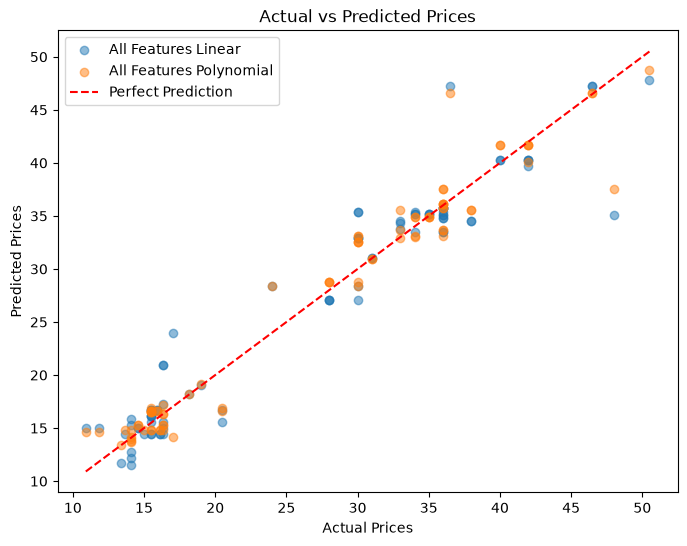

In [26]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test_v, all_model.predict(X_test_all), alpha=0.5, label="All Features Linear")
plt.scatter(y_test_v, full_poly_model.predict(X_test_all), alpha=0.5, label="All Features Polynomial")

# 完美预测参考线
all_values = np.concatenate([y_test_v, all_model.predict(X_test_all), full_poly_model.predict(X_test_all)])
low, high = all_values.min(), all_values.max()

plt.plot([low, high], [low, high], color='red', linestyle='--', label='Perfect Prediction')

plt.xlabel("Actual Prices")
plt.ylabel("Predicted Prices")
plt.title("Actual vs Predicted Prices")
plt.legend()
plt.show()

## Challenge：相关性与模型性能的关系

**相关系数的绝对值越大，模型在测试集上的预测效果就一定越好吗？**

我们设计三个模型，在同一批 PIE TYPE 数据上进行比较。

| 模型 | 输入特征 | 预测目标 |
| :--- | :--- | :--- |
| A | Month | Price |
| B | DayOfYear | Price |
| C | Month + DayOfYear | Price |

三个模型使用相同的数据划分和相同的线性回归算法，尽可能控制其他条件不变。

In [21]:
chanllenge_data = pie_pumpkins[
    ['Month', 'DayOfYear', 'Price'] 
].dropna().copy()

train_df, test_df = train_test_split(chanllenge_data, test_size=0.2, random_state=0)

feature_groups = [
    ['Month'],
    ['DayOfYear'],
    ['Month', 'DayOfYear']
]

results = []

for features in feature_groups:

    model = LinearRegression()

    model.fit(train_df[features], train_df['Price'])

    predictions = model.predict(test_df[features])

    # 单特征模型才计算一个 Pearson r
    corr = train_df[features[0]].corr(train_df['Price']) if len(features) == 1 else None

    results.append({
        'Features': '+'.join(features),
        'Train Correlation': corr,
        'Train R2': model.score(train_df[features], train_df['Price']),
        'Test R2': r2_score(test_df['Price'], predictions),
        'Test RMSE': np.sqrt(mean_squared_error(test_df['Price'], predictions))
    })

challenge_results = pd.DataFrame(results)
display(challenge_results.round(3))

,Features,Train Correlation,Train R2,Test R2,Test RMSE
0,Month,-0.197,0.039,0.077,2.808
1,DayOfYear,-0.211,0.045,0.102,2.769
2,Month+DayOfYear,NaN,0.045,0.103,2.767


## Assignment：独立创建回归模型

使用 Scikit-learn 自带的 Diabetes 数据集练习回归。

这是一个用于机器学习教学与研究的数据集，包含基线测量特征和一年后的定量疾病进展指标。本次只把它当作一个回归练习，不用于实际医疗判断。

### 实践任务
我们选择其中的 bmi 特征，分别训练线性回归和二次多项式回归，并判断哪一种方法更适合这组数据。

这样既符合官方 Assignment 的要求，也可以检验你能否把南瓜数据集上学到的方法迁移到新数据。

### 第一步：加载新数据

观察数据量、特征列以及缺失值情况

In [22]:
from sklearn.datasets import load_diabetes

diatetes = load_diabetes(as_frame=True)

df = diatetes.frame

print(df.shape)
print(df.head())
print(df.isnull().sum())

(442, 11)
        age       sex       bmi        bp        s1        s2        s3  \
0  0.038076  0.050680  0.061696  0.021872 -0.044223 -0.034821 -0.043401   
1 -0.001882 -0.044642 -0.051474 -0.026328 -0.008449 -0.019163  0.074412   
2  0.085299  0.050680  0.044451 -0.005670 -0.045599 -0.034194 -0.032356   
3 -0.089063 -0.044642 -0.011595 -0.036656  0.012191  0.024991 -0.036038   
4  0.005383 -0.044642 -0.036385  0.021872  0.003935  0.015596  0.008142   

         s4        s5        s6  target  
0 -0.002592  0.019907 -0.017646   151.0  
1 -0.039493 -0.068332 -0.092204    75.0  
2 -0.002592  0.002861 -0.025930   141.0  
3  0.034309  0.022688 -0.009362   206.0  
4 -0.002592 -0.031988 -0.046641   135.0  
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64


### 第二步：选择特征并训练模型

In [23]:
X = df[['bmi']]
y = df['target']

# 划分数据集
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=0
)

# 模型 1：线性回归
linear_model = LinearRegression()
linear_model.fit(X_train, y_train)

# 模型 2：多项式回归
poly_model = make_pipeline(PolynomialFeatures(2), LinearRegression())
poly_model.fit(X_train, y_train)

# 1. 用两个模型预测 X_test
linear_pred = linear_model.predict(X_test)
poly_pred = poly_model.predict(X_test)

# 2. 分别计算测试集 RMSE
linear_rmse = np.sqrt(mean_squared_error(y_test, linear_pred))
poly_rmse = np.sqrt(mean_squared_error(y_test, poly_pred))

# 3. 分别计算测试集 R²
linear_r2 = r2_score(y_test, linear_pred)
poly_r2 = r2_score(y_test, poly_pred)

# 4. 比较两个模型的性能
print(f"Linear Regression: RMSE={linear_rmse:.3f}, Test R²={linear_r2:.3f}")
print(f"Polynomial Regression: RMSE={poly_rmse:.3f}, Test R²={poly_r2:.3f}")

Linear Regression: RMSE=64.426, Test R²=0.191
Polynomial Regression: RMSE=64.409, Test R²=0.191


In [24]:
# Assignment：两个模型的结果比较

results = []

for name, model in [
    ("Linear", linear_model),
    ("Polynomial", poly_model)
]:
    pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Train R2": model.score(X_train, y_train),
        "Test R2": r2_score(y_test, pred),
        "Test RMSE": np.sqrt(
            mean_squared_error(y_test, pred)
        )
    })

assignment_results = pd.DataFrame(results)
display(assignment_results.round(3))


,Model,Train R2,Test R2,Test RMSE
0,Linear,0.376,0.191,64.426
1,Polynomial,0.376,0.191,64.409


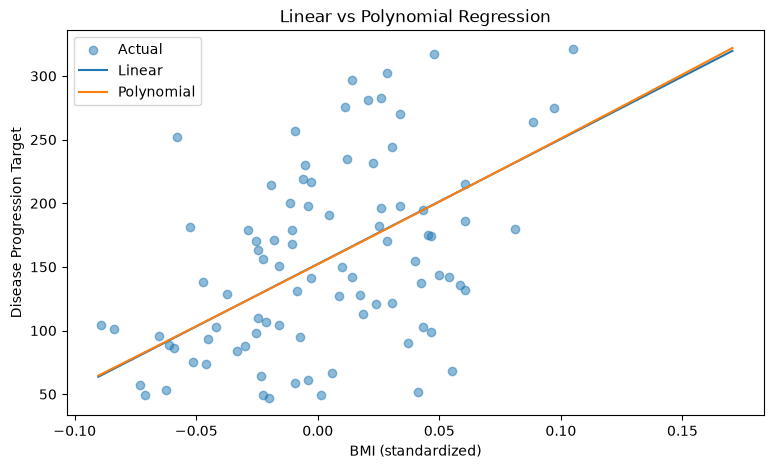

In [25]:
X_curve = np.linspace(
    X['bmi'].min(),
    X['bmi'].max(),
    200
).reshape(-1, 1)

plt.figure(figsize=(9, 5))

plt.scatter(
    X_test['bmi'], y_test,
    alpha=0.5,
    label="Actual"
)

for name, model in [
    ("Linear", linear_model),
    ("Polynomial", poly_model)
]:
    plt.plot(
        X_curve[:, 0],
        model.predict(
            pd.DataFrame(X_curve, columns=['bmi'])
        ),
        label=name
    )

plt.xlabel("BMI (standardized)")
plt.ylabel("Disease Progression Target")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.show()



---

**免责声明**：  
本文档使用AI翻译服务[Co-op Translator](https://github.com/Azure/co-op-translator)进行翻译。尽管我们努力确保准确性，但请注意，自动翻译可能包含错误或不准确之处。应以原始语言的文档作为权威来源。对于关键信息，建议使用专业人工翻译。因使用本翻译而导致的任何误解或误读，我们概不负责。
